# MissForest under grouped gaps

**A01.3 · Sprint 6 · Subteam A · Rishank Goyal**

At the same nominal 30% missingness, MissForest mean numeric skill falls from **0.656** with scattered gaps to **0.264** with grouped gaps. The same five fields break, and three of them fall below the median floor under grouped masking.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Study design and break rule

Compare mcar30-n05 with group30-n05 across the same nine generator–split pairs, both with ±5% measured noise, the model-only arm, and decay-corrected gas features enabled. The grouped scenario hides related blocks together, including location, gases, environment, and installation day plus model ID. Conditions share seeds and split blocks. The mask can change which cells are hidden and which helpers remain visible.

The mean numeric score weights 13 fields equally within each pair and excludes the placebo and Model ID. The field break analysis separately pools hidden-cell error and tolerance counts over pairs. A field breaks when pooled skill is below 0.10 or fewer than half of fills meet loose tolerance. Below-floor skill is strictly less than zero.

In [1]:
%matplotlib inline
from io import StringIO
from math import isclose
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
# Archived score extract. Rows and columns are restricted to this analysis.
evidence = pd.read_csv(StringIO("""
condition,generator_seed,split_seed,attribute,n,error,floor_error,skill,tolerance
Scattered,219,617,x,616,2.93806045580458,24.57792207792208,0.8804593632248598,0.7987012987012987
Scattered,219,617,y,606,13.14311883018708,29.12376237623763,0.5487149407278957,0.3201320132013201
Scattered,219,617,install_date,584,40.56736667299002,344.9332191780822,0.8823906645765948,0.6815068493150684
Scattered,219,617,altitude,597,12.63008066926847,34.99832495812395,0.6391232813461627,0.371859296482412
Scattered,219,617,measured_humid,618,0.0718844047525401,0.1741311408135003,0.5871823706161179,0.4692556634304207
Scattered,219,617,measured_salt,575,0.139510710400903,0.2162327144193579,0.3548121949283844,0.3008695652173913
Scattered,219,617,measured_overgrowth,616,0.09647228554927829,0.2972701719120389,0.6754727023946953,0.3198051948051948
Scattered,219,617,life,585,90.70276005747355,274.5333408604432,0.6696111307530345,0.9897435897435898
Scattered,219,617,measured_gas_a,578,198.4332304805347,1220.294894538314,0.8373891168694844,0.9740484429065744
Scattered,219,617,measured_gas_b,624,214.3855757913603,1059.373948919212,0.7976299341605678,0.966346153846154
Scattered,219,617,measured_gas_c,627,193.2302609013663,980.7439168797237,0.8029758252122162,0.9696969696969696
Scattered,219,617,total_gas,589,254.6399616435117,1156.240811604538,0.7797690938705556,0.99830220713073
Scattered,219,617,leakage,609,0.0879515833896141,0.09998389750598689,0.1203425193106951,0.6075533661740559
Scattered,219,631,x,570,2.293685660912289,25.88245614035088,0.9113806800840504,0.8649122807017544
Scattered,219,631,y,587,13.81183111967982,25.73253833049404,0.4632542292451469,0.3390119250425894
Scattered,219,631,install_date,591,31.60770632289029,339.1006768189509,0.906789610037358,0.727580372250423
Scattered,219,631,altitude,638,13.1223783380599,35.63949843260188,0.6318023845684664,0.3730407523510972
Scattered,219,631,measured_humid,605,0.0754007817307159,0.1716513402382546,0.5607329274210238,0.4677685950413223
Scattered,219,631,measured_salt,593,0.1269869896988256,0.2152094397975422,0.4099376411262982,0.342327150084317
Scattered,219,631,measured_overgrowth,554,0.09806453380996211,0.2931362468524875,0.6654643195342869,0.3231046931407942
Scattered,219,631,life,582,95.33864359699704,279.8650680217949,0.6593406805969353,0.9810996563573884
Scattered,219,631,measured_gas_a,594,221.2659484000851,1240.388415656093,0.8216155958832877,0.9646464646464646
Scattered,219,631,measured_gas_b,596,217.5354964199993,1089.91145382662,0.800409936370295,0.964765100671141
Scattered,219,631,measured_gas_c,627,171.4823623191263,990.0155742840516,0.8267882175054296,0.9840510366826156
Scattered,219,631,total_gas,587,242.6462739961031,1102.674572162893,0.7799475202188139,1
Scattered,219,631,leakage,572,0.08878669439022641,0.099290756221111,0.1057909339263476,0.5996503496503497
Scattered,219,653,x,603,2.470461914949645,24.78441127694859,0.9003219448166855,0.8275290215588723
Scattered,219,653,y,577,9.939601092169536,21.24783362218371,0.5322063760047453,0.3795493934142114
Scattered,219,653,install_date,599,34.31742375950533,354.0025041736227,0.9030588107289936,0.7295492487479132
Scattered,219,653,altitude,593,11.14132440996698,29.52107925801012,0.6225976593676213,0.3136593591905565
Scattered,219,653,measured_humid,617,0.06900462533092511,0.1827295049863342,0.6223673602350872,0.5040518638573744
Scattered,219,653,measured_salt,585,0.1227582851950553,0.2090002966413376,0.412640617416352,0.3811965811965812
Scattered,219,653,measured_overgrowth,564,0.08731023296785589,0.3263559278686487,0.7324692903908384,0.3953900709219858
Scattered,219,653,life,567,92.4153888057257,288.3500521776141,0.6795027845224704,0.9788359788359788
Scattered,219,653,measured_gas_a,592,189.4117666954088,1209.022164938691,0.8433347442352194,0.9746621621621622
Scattered,219,653,measured_gas_b,615,191.6943752247785,1061.448423208742,0.819403024175881,0.9707317073170731
Scattered,219,653,measured_gas_c,630,180.6111373112166,995.3032218080232,0.8185365692043812,0.9761904761904762
Scattered,219,653,total_gas,606,252.8198806377704,1103.182309907934,0.7708267451652036,0.9933993399339934
Scattered,219,653,leakage,612,0.08858137067292809,0.1015746857288105,0.1279188309828758,0.5980392156862745
Scattered,220,617,x,584,3.449408298238765,24.84931506849315,0.8611869868955734,0.7945205479452054
Scattered,220,617,y,586,14.7572854268267,29.23720136518771,0.4952565656849096,0.2559726962457337
Scattered,220,617,install_date,599,47.86953856356736,336.652754590985,0.8578073759659971,0.6427378964941569
Scattered,220,617,altitude,609,12.81852040876022,34.8128078817734,0.6317872303695593,0.3316912972085385
Scattered,220,617,measured_humid,578,0.0758880090849378,0.1802419403603323,0.5789658670272542,0.4532871972318339
Scattered,220,617,measured_salt,584,0.146156408228597,0.207185875986769,0.2945638425761675,0.3030821917808219
Scattered,220,617,measured_overgrowth,629,0.09201617715323469,0.299570842978257,0.6928400099341,0.3338632750397456
Scattered,220,617,life,595,94.7047332420895,272.2572154989839,0.6521497765687574,0.9831932773109244
Scattered,220,617,measured_gas_a,569,193.7020426610713,1227.054315280933,0.842140612482404,0.9736379613356766
Scattered,220,617,measured_gas_b,595,210.09893784568,1066.815621340026,0.8030597474924721,0.9714285714285714
Scattered,220,617,measured_gas_c,605,174.5315611702816,945.145029625917,0.8153388573186908,0.9851239669421488
Scattered,220,617,total_gas,594,276.0790630378805,1068.509921895511,0.7416223683275464,1
Scattered,220,617,leakage,600,0.0895476828634984,0.1011711155609459,0.1148888458232478,0.5833333333333334
Scattered,220,631,x,594,2.765295332585744,24.72727272727273,0.888168203461606,0.8080808080808081
Scattered,220,631,y,599,13.9482394674983,25.90317195325543,0.4615238823774502,0.348914858096828
Scattered,220,631,install_date,600,37.90403513533909,339.5383333333334,0.8883659622074903,0.7033333333333334
Scattered,220,631,altitude,606,14.92888006630024,33.37458745874587,0.5526872029578271,0.2937293729372937
Scattered,220,631,measured_humid,599,0.07461983012445041,0.1679047180772127,0.5555822910816854,0.4557595993322204
Scattered,220,631,measured_salt,620,0.1263935591204781,0.2075831468319625,0.391118397377447,0.3693548387096774
Scattered,220,631,measured_overgrowth,580,0.0958875377138135,0.2919745681172522,0.6715894184478879,0.3241379310344827
Scattered,220,631,life,618,92.97090191001068,284.7625250622748,0.6735142663534155,0.9789644012944984
Scattered,220,631,measured_gas_a,595,176.2143481902847,1218.715951786745,0.8554098287365985,0.9781512605042016
Scattered,220,631,measured_gas_b,632,186.6830298586071,1054.611049991877,0.8229839997788331,0.9778481012658228
Scattered,220,631,measured_gas_c,591,166.5063864135299,922.154156229811,0.8194375796187002,0.9813874788494078
Scattered,220,631,total_gas,583,254.4185377215737,1023.645765097593,0.7514584181400703,0.9982847341337908
Scattered,220,631,leakage,612,0.08756147794513899,0.0963134174457102,0.09086936932234251,0.5898692810457516
Scattered,220,653,x,569,3.020083134492516,25.20035149384886,0.8801571027598688,0.8084358523725835
Scattered,220,653,y,626,10.4798946752306,21.19488817891374,0.5055461209907781,0.3578274760383386
Scattered,220,653,install_date,573,41.93677589742045,344.5986038394415,0.8783025368351173,0.680628272251309
Scattered,220,653,altitude,600,11.88324030267029,29.49,0.5970416987904277,0.305
Scattered,220,653,measured_humid,584,0.07835423711702159,0.1728837013035385,0.5467806593320664,0.4434931506849315
Scattered,220,653,measured_salt,608,0.1497683177045282,0.2142355952195552,0.300917676397141,0.3223684210526316
Scattered,220,653,measured_overgrowth,581,0.101232705054425,0.3039601857515937,0.6669540624075161,0.3029259896729776
Scattered,220,653,life,581,104.1594493274044,278.5106119664708,0.6260126370339388,0.982788296041308
Scattered,220,653,measured_gas_a,573,192.1427044437931,1264.247047217481,0.8480180714151671,0.9685863874345548
Scattered,220,653,measured_gas_b,619,184.1577249060518,1057.660710782905,0.8258820404043051,0.974151857835218
Scattered,220,653,measured_gas_c,607,162.5819251284633,930.8848419507208,0.8253468981321429,0.9818780889621088
Scattered,220,653,total_gas,622,242.6409287287455,1067.785898676155,0.7727625650146039,0.9983922829581994
Scattered,220,653,leakage,550,0.0893445025495551,0.1034524527837668,0.1363713460105162,0.5745454545454546
Scattered,221,617,x,600,2.897512856593855,24.99833333333333,0.8840917585201471,0.805
Scattered,221,617,y,583,12.91257950141891,28.38078902229845,0.545023942383221,0.3756432246998284
Scattered,221,617,install_date,603,37.32487059977595,336.2504145936982,0.888996804227359,0.6915422885572139
Scattered,221,617,altitude,617,13.46514704075967,35.16045380875202,0.6170371658454541,0.3338735818476499
Scattered,221,617,measured_humid,610,0.07194791346378859,0.1713619112442683,0.5801405753392288,0.4590163934426229
Scattered,221,617,measured_salt,597,0.1274676965986425,0.2053399690429569,0.3792358244099257,0.3668341708542713
Scattered,221,617,measured_overgrowth,618,0.0931642220450712,0.2988041379067749,0.6882097326438703,0.3915857605177993
Scattered,221,617,life,591,83.87453347519764,287.4906744309658,0.7082530289331588,0.9898477157360406
Scattered,221,617,measured_gas_a,620,209.8607331984527,1273.119651315581,0.835160243594078,0.9693548387096774
Scattered,221,617,measured_gas_b,614,204.9310730213661,1092.573134712435,0.8124326266952338,0.970684039087948
Scattered,221,617,measured_gas_c,574,182.9753856756472,950.4269253612144,0.8074808480345751,0.9738675958188152
Scattered,221,617,total_gas,580,258.6416036731848,1064.668130437448,0.7570683330523711,0.996551724137931
Scattered,221,617,leakage,642,0.0864676162961009,0.0984679006585243,0.1218700132953883,0.616822429906542
Scattered,221,631,x,570,2.776813827662744,24.35789473684211,0.8859994323128951,0.8350877192982457
Scattered,221,631,y,632,13.68733708982037,25.57594936708861,0.4648356198486467,0.3196202531645569
Scattered,221,631,install_date,637,35.08892774365601,343.3971742543171,0.8978182397107629,0.7111459968602826
Scattered,221,631,altitude,613,13.80978079528745,33.95269168026101,0.5932640355781864,0.298531810766721
Scattered,221,631,measured_humid,589,0.06780600408707591,0.1745855587464715,0.6116173378031682,0.4448217317487266
Scattered,221,631,measured_salt,608,0.1340556574191197,0.1988111276556108,0.3257135101042397,0.3733552631578947
Scattered,221,631,measured_overgrowth,598,0.0928267699769173,0.2831033582396404,0.6721099652292305,0.3160535117056856
Scattered,221,631,life,579,96.76709444222068,285.8070694871114,0.661425119344067,0.9810017271157168
Scattered,221,631,measured_gas_a,590,198.1114553615871,1273.565946889698,0.8444435045979246,0.9745762711864406
Scattered,221,631,measured_gas_b,600,196.1672981785284,1065.032377058519,0.8158109533530644,0.9783333333333334
Scattered,221,631,measured_gas_c,592,176.2055025346098,929.743034416504,0.8104793518080031,0.983108108108108
Scattered,221,631,total_gas,597,248.1901356944955,1135.697834776518,0.7814646395417897,0.9983249581239531
Scattered,221,631,leakage,601,0.0841278172747066,0.0978784504363145,0.140486829330782,0.627287853577371
Scattered,221,653,x,584,2.854172222878344,24.11815068493151,0.881658744894501,0.8184931506849316
Scattered,221,653,y,619,10.58208245611124,21.12600969305331,0.4990969610512457,0.332794830371567
Scattered,221,653,install_date,617,36.70893246263707,347.7811993517018,0.894448197513074,0.6855753646677472
Scattered,221,653,altitude,585,11.81504047615186,28.4017094017094,0.5840024869967598,0.3042735042735042
Scattered,221,653,measured_humid,599,0.0738532525664758,0.168862766240481,0.5626433570246039,0.4507512520868113
Scattered,221,653,measured_salt,590,0.1461759920293118,0.2149743264750568,0.3200304686323908,0.2745762711864407
Scattered,221,653,measured_overgrowth,586,0.1050176327679048,0.3110373992684573,0.6623633266774336,0.2832764505119454
Scattered,221,653,life,598,92.19685964275668,319.255608067339,0.7112130302083525,0.9866220735785952
Scattered,221,653,measured_gas_a,570,182.4226999895599,1254.040807848105,0.8545320863181545,0.9771929824561404
Scattered,221,653,measured_gas_b,559,179.9641469398614,1067.402903212183,0.8313999836441448,0.9785330948121646
Scattered,221,653,measured_gas_c,591,193.083292760998,960.4717393202434,0.7989703550281977,0.9746192893401016
Scattered,221,653,total_gas,602,245.0361222938442,1045.162597849416,0.7655521516001014,0.9950166112956812
Scattered,221,653,leakage,587,0.0873957287789819,0.09836024631508219,0.1114730589528737,0.6013628620102215
Grouped,219,617,x,616,6.241519475012032,24.57792207792208,0.7460517835794311,0.6623376623376623
Grouped,219,617,y,616,43.19231685166987,29.15422077922078,-0.4815116198356612,0.0389610389610389
Grouped,219,617,install_date,584,126.6109023506692,344.9332191780822,0.6329408264812486,0.5856164383561644
Grouped,219,617,altitude,616,57.06928099694482,34.80681818181818,-0.6396006293604781,0.0178571428571428
Grouped,219,617,measured_humid,618,0.1510462736860719,0.1741311408135003,0.132571733117817,0.1925566343042071
Grouped,219,617,measured_salt,618,0.2361084453261425,0.2130426401950365,-0.1082684908053603,0.145631067961165
Grouped,219,617,measured_overgrowth,618,0.2908272100010191,0.3024526013078155,0.0384370683423712,0.0663430420711974
Grouped,219,617,life,585,119.2238801848504,274.5333408604432,0.5657216722341316,0.9572649572649572
Grouped,219,617,measured_gas_a,578,435.2543706311693,1220.294894538314,0.6433203379123837,0.8494809688581315
Grouped,219,617,measured_gas_b,578,318.2883163641815,1071.822197794574,0.7030400032588384,0.8944636678200693
Grouped,219,617,measured_gas_c,578,369.9572114349996,940.3725586277438,0.606584424395724,0.8633217993079585
Grouped,219,617,total_gas,578,366.0513861329392,1029.391972705912,0.6444003879584197,0.967128027681661
Grouped,219,617,leakage,609,0.0901719597027469,0.09998389750598689,0.0981351802439234,0.5714285714285714
Grouped,219,631,x,570,4.669007352852335,25.88245614035088,0.8196072533636662,0.7456140350877193
Grouped,219,631,y,570,45.33412285430643,25.84736842105263,-0.7539163800281454,0.0491228070175438
Grouped,219,631,install_date,591,69.76182476078317,339.1006768189509,0.7942740031803898,0.6615905245346869
Grouped,219,631,altitude,570,61.60871377108234,36.17543859649123,-0.7030536784440802,0.0473684210526315
Grouped,219,631,measured_humid,605,0.1712666730118715,0.1716513402382546,0.0022409800345811,0.1735537190082644
Grouped,219,631,measured_salt,605,0.2139946732425187,0.2090268688159058,-0.023766343794721,0.168595041322314
Grouped,219,631,measured_overgrowth,605,0.3097210635029086,0.3097747553152245,0.0001733253320183,0.0429752066115702
Grouped,219,631,life,582,131.2937125845795,279.8650680217949,0.530867808860108,0.9467353951890034
Grouped,219,631,measured_gas_a,594,439.0933263327751,1240.388415656093,0.6460033641151668,0.8653198653198653
Grouped,219,631,measured_gas_b,594,390.5382905044094,1059.464002159312,0.631381255324913,0.8939393939393939
Grouped,219,631,measured_gas_c,594,387.0419982120578,948.6661002885344,0.5920145158614396,0.8888888888888888
Grouped,219,631,total_gas,594,331.1703299673151,1106.726668304575,0.7007659258137837,0.9730639730639732
Grouped,219,631,leakage,572,0.0898058431876487,0.099290756221111,0.095526647136621,0.5926573426573427
Grouped,219,653,x,603,7.818947709808137,24.78441127694859,0.6845215477407623,0.7512437810945274
Grouped,219,653,y,603,38.07113036182056,21.09121061359867,-0.8050708922926404,0.0563847429519071
Grouped,219,653,install_date,599,214.0196292201576,354.0025041736227,0.3954290529109073,0.4357262103505843
Grouped,219,653,altitude,603,52.92956262680884,28.91044776119403,-0.8308108910666971,0.0298507462686567
Grouped,219,653,measured_humid,617,0.1828727709850971,0.1827295049863342,-0.0007840332012811,0.1620745542949757
Grouped,219,653,measured_salt,617,0.2103430501161548,0.2095198943996332,-0.0039287711502542,0.1620745542949757
Grouped,219,653,measured_overgrowth,617,0.3185357738939803,0.3194768492809504,0.0029456763114077,0.0551053484602917
Grouped,219,653,life,567,140.579099273101,288.3500521776141,0.5124706993758097,0.9470899470899472
Grouped,219,653,measured_gas_a,592,502.6981793114861,1209.022164938691,0.5842109484097195,0.8327702702702703
Grouped,219,653,measured_gas_b,592,497.6618770133407,1100.286106962521,0.5476977543711796,0.847972972972973
Grouped,219,653,measured_gas_c,592,511.0990317624969,976.7176663847134,0.4767177359919041,0.8277027027027027
Grouped,219,653,total_gas,592,407.3641045848142,1069.906107539588,0.6192524729841853,0.9493243243243245
Grouped,219,653,leakage,612,0.09123759730761009,0.1015746857288105,0.1017683524889161,0.5849673202614379
Grouped,220,617,x,584,5.370472313649566,24.84931506849315,0.7838784570582038,0.708904109589041
Grouped,220,617,y,584,40.22679153068722,28.46746575342466,-0.4130794739200805,0.0410958904109589
Grouped,220,617,install_date,599,69.86670446775597,336.652754590985,0.792466559340528,0.671118530884808
Grouped,220,617,altitude,584,53.98279568690072,34.375,-0.5704086018007484,0.0188356164383561
Grouped,220,617,measured_humid,578,0.1376348349356487,0.1802419403603323,0.2363884084886414,0.2664359861591695
Grouped,220,617,measured_salt,578,0.2273213415386351,0.2076044734261193,-0.0949732334141271,0.1695501730103806
Grouped,220,617,measured_overgrowth,578,0.2391461011694017,0.3089310307613209,0.2258916154196073,0.0536332179930795
Grouped,220,617,life,595,115.2077216051939,272.2572154989839,0.5768423569819994,0.9630252100840336
Grouped,220,617,measured_gas_a,569,336.473524147575,1227.054315280933,0.7257875874300319,0.8945518453427065
Grouped,220,617,measured_gas_b,569,362.4042356436999,1029.519228715724,0.6479869190051147,0.8875219683655536
Grouped,220,617,measured_gas_c,569,334.1623083653358,930.9593177515488,0.6410559494990565,0.905096660808436
Grouped,220,617,total_gas,569,312.0920013241015,1100.797268993447,0.716485487278258,0.9824253075571178
Grouped,220,617,leakage,600,0.089247851127982,0.1011711155609459,0.1178524558798728,0.585
Grouped,220,631,x,594,5.849140775397911,24.72727272727273,0.7634538657008197,0.6717171717171717
Grouped,220,631,y,594,42.12111392737228,26.96464646464646,-0.5620866375013507,0.0555555555555555
Grouped,220,631,install_date,600,108.7555393106841,339.5383333333334,0.6796958439331324,0.5533333333333333
Grouped,220,631,altitude,594,57.29368532118985,35.63804713804713,-0.6076550182241378,0.0572390572390572
Grouped,220,631,measured_humid,599,0.1688997098685997,0.1679047180772127,-0.0059259311041479,0.1786310517529215
Grouped,220,631,measured_salt,599,0.2116504478504964,0.2118144377799472,0.0007742150684799,0.1419031719532554
Grouped,220,631,measured_overgrowth,599,0.280776608691344,0.2791581308153666,-0.0057977099619135,0.0634390651085141
Grouped,220,631,life,618,132.4849271686289,284.7625250622748,0.5347529414565497,0.9514563106796116
Grouped,220,631,measured_gas_a,595,566.2574480078302,1218.715951786745,0.5353655237074342,0.8168067226890756
Grouped,220,631,measured_gas_b,595,435.4476743445808,1066.065805926901,0.5915377156610172,0.8773109243697479
Grouped,220,631,measured_gas_c,595,503.5841628359415,961.0981677811128,0.4760325430662653,0.8336134453781513
Grouped,220,631,total_gas,595,414.2503460392692,1044.883284127964,0.6035439054946763,0.9445378151260504
Grouped,220,631,leakage,612,0.0870918937277301,0.0963134174457102,0.0957449539486858,0.6111111111111112
Grouped,220,653,x,569,4.425336567713689,25.20035149384886,0.8243938554272202,0.7785588752196837
Grouped,220,653,y,569,35.88597446440304,21.68541300527241,-0.6548439476655588,0.0667838312829525
Grouped,220,653,install_date,573,141.2252816309786,344.5986038394415,0.5901745391377746,0.5287958115183246
Grouped,220,653,altitude,569,48.35609447934313,28.47451669595782,-0.6982235377574524,0.0544815465729349
Grouped,220,653,measured_humid,584,0.1574994725386523,0.1728837013035385,0.0889859983844023,0.1678082191780822
Grouped,220,653,measured_salt,584,0.2203553996151763,0.211453463215251,-0.0420987968916046,0.172945205479452
Grouped,220,653,measured_overgrowth,584,0.2638367692569427,0.2961415049670782,0.1090854715340449,0.06335616438356161
Grouped,220,653,life,581,130.9582744763779,278.5106119664708,0.5297907194568816,0.9604130808950088
Grouped,220,653,measured_gas_a,573,465.9673099209097,1264.247047217481,0.6314270134571631,0.837696335078534
Grouped,220,653,measured_gas_b,573,346.1468287955366,1062.403362195423,0.6741851154534798,0.8848167539267016
Grouped,220,653,measured_gas_c,573,398.1783273723236,962.5936356567216,0.5863484728935802,0.8481675392670157
Grouped,220,653,total_gas,573,342.4247018875408,1036.172749880857,0.669529330966372,0.9633507853403142
Grouped,220,653,leakage,550,0.0934815800333373,0.1034524527837668,0.0963812116786662,0.5781818181818181
Grouped,221,617,x,600,5.632369441045027,24.99833333333333,0.7746902017049793,0.7383333333333333
Grouped,221,617,y,600,40.95524319912238,29.205,-0.4023366957412218,0.0316666666666666
Grouped,221,617,install_date,603,66.59269317431971,336.2504145936982,0.8019550600263624,0.6517412935323383
Grouped,221,617,altitude,600,59.85244224020929,34.23,-0.7485376056152291,0.0116666666666666
Grouped,221,617,measured_humid,610,0.1702100393395328,0.1713619112442683,0.0067218665826714,0.1540983606557377
Grouped,221,617,measured_salt,610,0.209236882224456,0.208139502372448,-0.0052723286041314,0.1327868852459016
Grouped,221,617,measured_overgrowth,610,0.2808284989056548,0.2810705544948891,0.0008611915597823,0.0524590163934426
Grouped,221,617,life,591,117.1454901446307,287.4906744309658,0.5925242083886779,0.9729272419627748
Grouped,221,617,measured_gas_a,620,524.1298614354866,1273.119651315581,0.5883106030969864,0.8290322580645161
Grouped,221,617,measured_gas_b,620,406.5961053319784,1044.063371130062,0.6105637678947673,0.8806451612903226
Grouped,221,617,measured_gas_c,620,389.2230869850856,963.6248251461188,0.5960844129082437,0.8806451612903226
Grouped,221,617,total_gas,620,365.4562363685536,1038.580948417774,0.6481196415885465,0.9548387096774194
Grouped,221,617,leakage,642,0.0858976134218937,0.0984679006585243,0.1276587309424107,0.632398753894081
Grouped,221,631,x,570,6.70627200493648,24.35789473684211,0.7246776834619855,0.6789473684210526
Grouped,221,631,y,570,43.83100401853176,26.49298245614035,-0.6544382683638901,0.0403508771929824
Grouped,221,631,install_date,637,87.60259491811482,343.3971742543171,0.7448942464120656,0.6499215070643642
Grouped,221,631,altitude,570,57.95020188647008,34.43333333333333,-0.6829681089971953,0.06315789473684209
Grouped,221,631,measured_humid,589,0.1766158505446568,0.1745855587464715,-0.0116292081244453,0.1561969439728353
Grouped,221,631,measured_salt,589,0.2054837569115935,0.2047994662706613,-0.0033412716028653,0.1544991511035653
Grouped,221,631,measured_overgrowth,589,0.2699093978858801,0.2659766367008835,-0.0147861151783019,0.0696095076400679
Grouped,221,631,life,579,129.3766847218018,285.8070694871114,0.5473286054331274,0.9550949913644214
Grouped,221,631,measured_gas_a,590,524.9364366206041,1273.565946889698,0.5878215510530855,0.8372881355932204
Grouped,221,631,measured_gas_b,590,387.7244525098596,1089.130330194369,0.6440054585196747,0.8745762711864407
Grouped,221,631,measured_gas_c,590,424.10861244691,980.8454007333314,0.5676091133935846,0.8661016949152542
Grouped,221,631,total_gas,590,390.0694820763164,1053.166006569682,0.6296220352318143,0.9423728813559322
Grouped,221,631,leakage,601,0.08688703435568319,0.0978784504363145,0.1122965885916115,0.6056572379367721
Grouped,221,653,x,584,7.227128507823832,24.11815068493151,0.7003448314824907,0.7208904109589042
Grouped,221,653,y,584,31.40943687733143,21.6027397260274,-0.453956177580973,0.0736301369863013
Grouped,221,653,install_date,617,111.9482067733634,347.7811993517018,0.6781073646820305,0.6045380875202593
Grouped,221,653,altitude,584,42.79382002666948,28.00856164383562,-0.5278835297166335,0.06678082191780819
Grouped,221,653,measured_humid,599,0.1461369643742277,0.168862766240481,0.1345814851445049,0.2320534223706176
Grouped,221,653,measured_salt,599,0.2115941688511856,0.2056460737201965,-0.0289239421078475,0.1719532554257095
Grouped,221,653,measured_overgrowth,599,0.2511523257674785,0.2925047295632765,0.1413734535422356,0.0651085141903172
Grouped,221,653,life,598,120.8548719565856,319.255608067339,0.6214479279214595,0.9615384615384616
Grouped,221,653,measured_gas_a,570,446.0520037135088,1254.040807848105,0.6443082227292745,0.8614035087719298
Grouped,221,653,measured_gas_b,570,334.1750178480901,1098.720813806138,0.695850835217678,0.8982456140350877
Grouped,221,653,measured_gas_c,570,359.6533035373274,974.7026407945272,0.631012281608105,0.8929824561403509
Grouped,221,653,total_gas,570,384.5671213718979,1064.603022289168,0.6387694630577128,0.9473684210526316
Grouped,221,653,leakage,587,0.0895119081909939,0.09836024631508219,0.089958478710434,0.6013628620102215
"""))

In [3]:
def pooled_field_scores(rows):
    """Pool absolute errors and in-tolerance counts by condition and target."""
    counts = rows.assign(
        absolute_error_sum=rows.n * rows.error,
        floor_absolute_error_sum=rows.n * rows.floor_error,
        within_loose_n=(rows.n * rows.tolerance).round().astype(int),
    )
    totals = counts.groupby(["condition", "attribute"])[
        ["n", "absolute_error_sum", "floor_absolute_error_sum", "within_loose_n"]
    ].sum()
    totals["pooled_mae"] = totals.absolute_error_sum / totals.n
    totals["pooled_skill"] = 1 - totals.absolute_error_sum / totals.floor_absolute_error_sum
    totals["within_loose"] = totals.within_loose_n / totals.n
    totals["breaks"] = totals.pooled_skill.lt(0.10) | totals.within_loose.lt(0.50)
    totals["below_floor"] = totals.pooled_skill.lt(0)
    return totals

pair_scores = evidence.groupby(["condition", *PAIR]).skill.mean().unstack("condition")
pooled = pooled_field_scores(evidence)
assert len(pair_scores) == 9 and pair_scores.notna().all().all()

## Paired mean scores and pooled field results

In [4]:
headline = pair_scores[["Scattered", "Grouped"]].copy()
headline["Paired change"] = headline.Grouped - headline.Scattered
assert tuple(headline.mean().round(3)) == (0.656, 0.264, -0.392)
display(headline.style.format(precision=3))
display(headline.mean().to_frame("Mean across nine pairs").style.format(precision=3))

by_condition = pooled.groupby(level="condition")[["breaks", "below_floor"]].sum()
assert by_condition.loc["Scattered"].tolist() == [5, 0]
assert by_condition.loc["Grouped"].tolist() == [5, 3]
under = pooled.xs("Grouped").query("below_floor").index
assert set(under) == {"y", "altitude", "measured_salt"}
display(by_condition.loc[["Scattered", "Grouped"]].rename(columns={
    "breaks": "Fields that break", "below_floor": "Fields below median floor",
}))

scores = pooled[["pooled_skill", "within_loose"]].unstack("condition").sort_values(
    ("pooled_skill", "Grouped")
)
scores.index = scores.index.map(FIELD)
scores.columns = [f"{condition} {'skill' if metric == 'pooled_skill' else 'within loose'}"
                  for metric, condition in scores.columns]
display(scores.style.format({col: "{:.3f}" if col.endswith("skill") else "{:.1%}"
                             for col in scores}))

,Mean across nine pairs
condition,
Scattered,0.656
Grouped,0.264
Paired change,-0.392


,Fields that break,Fields below median floor
condition,,
Scattered,5,0
Grouped,5,3


,Grouped skill,Scattered skill,Grouped within loose,Scattered within loose
attribute,,,,
Altitude,-0.667,0.609,4.0%,32.5%
y,-0.565,0.502,5.0%,33.6%
Salt,-0.034,0.354,15.8%,33.8%
Overgrowth,0.056,0.681,5.9%,33.2%
Humidity,0.065,0.579,18.7%,46.1%
Leakage,0.104,0.119,59.6%,60.0%
Life,0.558,0.672,95.7%,98.4%
Gas C,0.574,0.814,86.7%,97.9%
Gas A,0.620,0.842,84.7%,97.3%


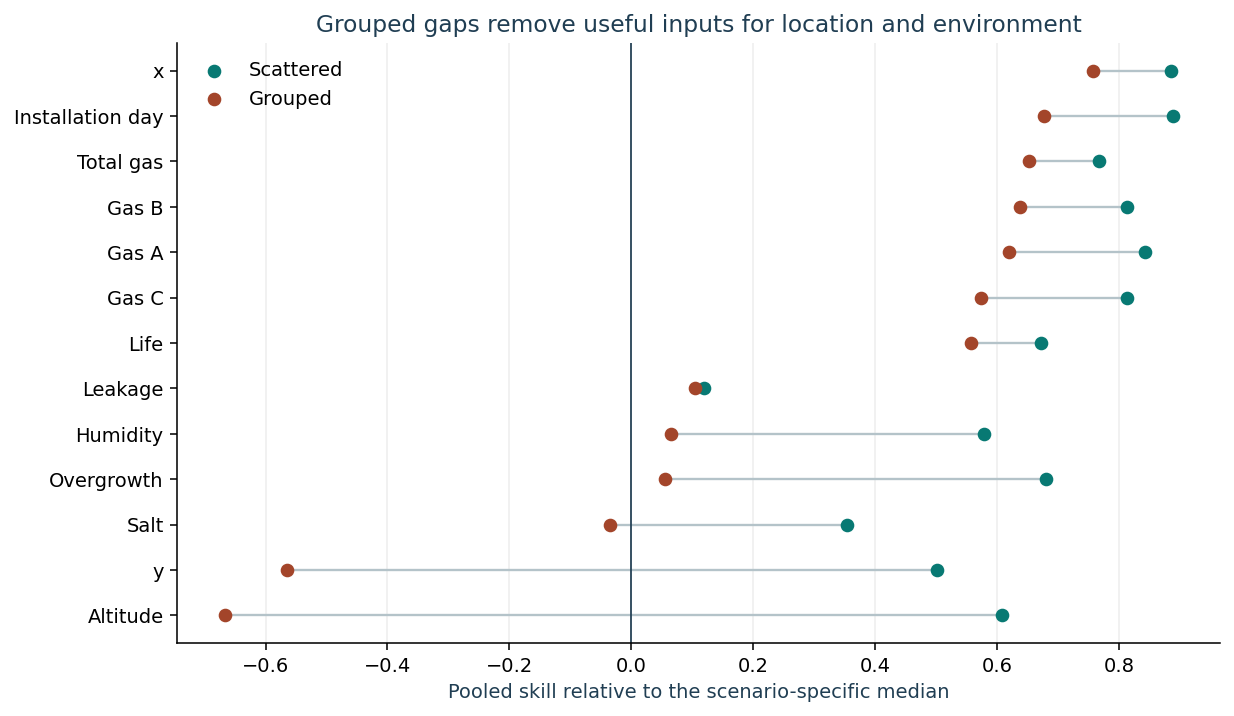

In [5]:
fig, ax = plt.subplots(figsize=(8.7, 5.0), layout="constrained")
positions = range(len(scores))
ax.hlines(positions, scores["Grouped skill"], scores["Scattered skill"],
          color="#b4c3c9", linewidth=1.2)
ax.scatter(scores["Scattered skill"], positions, color=TEAL, label="Scattered", zorder=3)
ax.scatter(scores["Grouped skill"], positions, color=RUST, label="Grouped", zorder=3)
ax.axvline(0, color=NAVY, linewidth=0.9)
ax.set(yticks=list(positions), yticklabels=scores.index,
       xlabel="Pooled skill relative to the scenario-specific median",
       title="Grouped gaps remove useful inputs for location and environment")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x")
plt.show()

## Interpretation

At the anchor, y, altitude, humidity, salt, and overgrowth fail only the tolerance criterion. Under grouped gaps the same five fail both criteria. y, altitude, and salt go below the scenario-specific median floor. In the synthetic data, losing x, y, and altitude together also removes the inputs to their exact identity.

The break count stays at five while the errors get substantially worse. Pair means, field-level pooled skill, and below-floor counts show different parts of that change. These are controlled synthetic conditions. The results describe how this benchmark responds when helpers disappear together.

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | MissForest scattered anchor with domain features, model only, group all | 9d8119486d0cbae0 |
| anchor-stress/tables/cells.csv | Matched grouped scenario with domain features, model only, group all | f4b3c14586d8bf47 |

[Sections 8 and 8A of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)